# Problema 3 — Planejamento de Capacidade de Servidores
**Projeto de Métodos Numéricos — 2º GQ**

## Objetivo
A empresa possui capacidade atual de **600 TB**. Usaremos os 12 registros históricos para modelar o crescimento do armazenamento, estimar o próximo mês e identificar quando a demanda ultrapassa a capacidade atual e cada opção de expansão.

Os dados dos CSVs foram mantidos conforme os arquivos fornecidos no repositório do professor.

## 1. Bibliotecas e métodos do pacote

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Localiza a raiz do repositório mesmo quando o notebook está em notebook/.
RAIZ = Path.cwd()
if RAIZ.name == "notebook":
    RAIZ = RAIZ.parent
if not (RAIZ / "armazenamento.csv").exists() and not (RAIZ / "dados" / "armazenamento.csv").exists():
    if (RAIZ.parent / "armazenamento.csv").exists() or (RAIZ.parent / "dados" / "armazenamento.csv").exists():
        RAIZ = RAIZ.parent

def localizar_arquivo(nome):
    candidatos = [
        RAIZ / nome,
        RAIZ / "dados" / nome,
        RAIZ.parent / nome,
        RAIZ.parent / "dados" / nome,
    ]
    for caminho in candidatos:
        if caminho.exists():
            return caminho
    raise FileNotFoundError(f"Não encontrei {nome}. Verifique se o CSV está na raiz do repositório ou em dados/.")

# Métodos numéricos implementados aqui provisoriamente.
# Na integração final, estas funções serão movidas para o pacote Python do grupo.
def resolver_gauss(A, b, tolerancia=1e-12):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float).reshape(-1)
    n = len(b)
    if A.shape != (n, n):
        raise ValueError("A matriz A deve ser quadrada e compatível com b.")
    M = np.column_stack((A, b))
    for k in range(n):
        pivo = k + int(np.argmax(np.abs(M[k:, k])))
        if abs(M[pivo, k]) < tolerancia:
            raise ValueError("Sistema singular ou mal condicionado.")
        if pivo != k:
            M[[k, pivo]] = M[[pivo, k]]
        for i in range(k + 1, n):
            fator = M[i, k] / M[k, k]
            M[i, k:] -= fator * M[k, k:]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (M[i, -1] - np.dot(M[i, i+1:n], x[i+1:n])) / M[i, i]
    return x

def avaliar_polinomio(coeficientes, x):
    coeficientes = np.asarray(coeficientes, dtype=float)
    return np.polynomial.polynomial.polyval(x, coeficientes)

def ajuste_polinomial_minimos_quadrados(x, y, grau=2):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or len(x) != len(y):
        raise ValueError("x e y devem ser vetores unidimensionais de mesmo tamanho.")
    if grau < 0 or len(x) < grau + 1:
        raise ValueError("Quantidade de dados insuficiente para o grau solicitado.")
    V = np.vander(x, N=grau + 1, increasing=True)
    # Equações normais: (VᵀV)a = Vᵀy, resolvidas pelo Gauss implementado acima.
    return resolver_gauss(V.T @ V, V.T @ y)

def interpolacao_lagrange(x, y, ponto):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) != len(y) or len(np.unique(x)) != len(x):
        raise ValueError("Os pontos x devem ser distintos e ter o mesmo tamanho de y.")
    resultado = 0.0
    for i in range(len(x)):
        termo = y[i]
        for j in range(len(x)):
            if i != j:
                termo *= (ponto - x[j]) / (x[i] - x[j])
        resultado += termo
    return float(resultado)

def trapezios_composto(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) != len(y) or len(x) < 2 or np.any(np.diff(x) <= 0):
        raise ValueError("Forneça ao menos dois pontos x crescentes e y correspondentes.")
    return float(np.sum(np.diff(x) * (y[:-1] + y[1:]) / 2))

def simpson_composto(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if len(x) != len(y) or len(x) < 2 or np.any(np.diff(x) <= 0):
        raise ValueError("Forneça ao menos dois pontos x crescentes e y correspondentes.")
    h = np.diff(x)
    if not np.allclose(h, h[0]):
        raise ValueError("A regra de Simpson composta exige espaçamento uniforme.")
    n = len(x) - 1
    passo = h[0]
    if n == 1:
        return trapezios_composto(x, y)
    # Com número ímpar de subintervalos: Simpson 1/3 no início e 3/8 nos últimos três.
    if n % 2 == 0:
        limite = n
        resultado = y[0] + y[n]
        resultado += 4 * np.sum(y[1:n:2]) + 2 * np.sum(y[2:n-1:2])
        return float(passo * resultado / 3)
    limite = n - 3
    resultado = 0.0
    if limite > 0:
        resultado += (passo / 3) * (y[0] + y[limite] + 4*np.sum(y[1:limite:2]) + 2*np.sum(y[2:limite-1:2]))
    resultado += (3 * passo / 8) * (y[limite] + 3*y[limite+1] + 3*y[limite+2] + y[limite+3])
    return float(resultado)

plt.style.use("default")


## 2. Leitura dos arquivos

In [2]:
arquivo_armazenamento = localizar_arquivo("armazenamento.csv")
arquivo_expansoes = localizar_arquivo("expansoes.csv")

armazenamento = pd.read_csv(arquivo_armazenamento)
expansoes = pd.read_csv(arquivo_expansoes)

display(armazenamento)
display(expansoes)


,mes,armazenamento_tb
0,1,137.99
1,2,150.45
2,3,172.59
3,4,199.09
4,5,219.06
5,6,250.06
6,7,292.32
7,8,328.07
8,9,366.12
9,10,417.17


,plano,capacidade_adicional_tb
0,A,100
1,B,200
2,C,300


## 3. Conferência e preparação dos dados

In [3]:
colunas_armazenamento = {"mes", "armazenamento_tb"}
colunas_expansoes = {"plano", "capacidade_adicional_tb"}
if not colunas_armazenamento.issubset(armazenamento.columns):
    raise ValueError(f"Colunas esperadas em armazenamento.csv: {colunas_armazenamento}")
if not colunas_expansoes.issubset(expansoes.columns):
    raise ValueError(f"Colunas esperadas em expansoes.csv: {colunas_expansoes}")

armazenamento["mes"] = pd.to_numeric(armazenamento["mes"], errors="raise")
armazenamento["armazenamento_tb"] = pd.to_numeric(armazenamento["armazenamento_tb"], errors="raise")
expansoes["capacidade_adicional_tb"] = pd.to_numeric(expansoes["capacidade_adicional_tb"], errors="raise")
armazenamento = armazenamento.sort_values("mes").reset_index(drop=True)

if armazenamento.isna().any().any() or expansoes.isna().any().any():
    raise ValueError("Existem valores ausentes nos arquivos CSV.")
if armazenamento["mes"].duplicated().any():
    raise ValueError("Existem meses duplicados.")
if (armazenamento["armazenamento_tb"] < 0).any() or (expansoes["capacidade_adicional_tb"] < 0).any():
    raise ValueError("Capacidades não podem ser negativas.")
if len(armazenamento) < 3:
    raise ValueError("São necessários ao menos três meses para o ajuste quadrático.")

display(armazenamento.isna().sum().to_frame("valores_ausentes"))
display(expansoes)

,valores_ausentes
mes,0
armazenamento_tb,0


,plano,capacidade_adicional_tb
0,A,100
1,B,200
2,C,300


## 4. Análise descritiva do armazenamento

In [4]:
meses = armazenamento["mes"].to_numpy(dtype=float)
valores = armazenamento["armazenamento_tb"].to_numpy(dtype=float)
primeiro_valor = valores[0]
ultimo_valor = valores[-1]
crescimento_absoluto = ultimo_valor - primeiro_valor
crescimento_percentual = crescimento_absoluto / primeiro_valor * 100

print(f"Meses observados: {len(valores)}")
print(f"Armazenamento no mês {int(meses[0])}: {primeiro_valor:.2f} TB")
print(f"Armazenamento no mês {int(meses[-1])}: {ultimo_valor:.2f} TB")
print(f"Crescimento absoluto: {crescimento_absoluto:.2f} TB")
print(f"Crescimento percentual: {crescimento_percentual:.2f}%")
display(armazenamento["armazenamento_tb"].describe().to_frame("armazenamento_tb"))

Meses observados: 12
Armazenamento no mês 1: 137.99 TB
Armazenamento no mês 12: 519.14 TB
Crescimento absoluto: 381.15 TB
Crescimento percentual: 276.22%


,armazenamento_tb
count,12.000000
mean,293.017500
std,126.994608
min,137.990000
25%,192.465000
50%,271.190000
75%,378.882500
max,519.140000


## 5. Variação mensal e visualização

,mes,armazenamento_tb,aumento_tb,aumento_percentual
0,1,137.99,NaN,NaN
1,2,150.45,12.46,9.029640
2,3,172.59,22.14,14.715852
3,4,199.09,26.50,15.354308
4,5,219.06,19.97,10.030639
5,6,250.06,31.00,14.151374
6,7,292.32,42.26,16.899944
7,8,328.07,35.75,12.229748
8,9,366.12,38.05,11.598135
9,10,417.17,51.05,13.943516


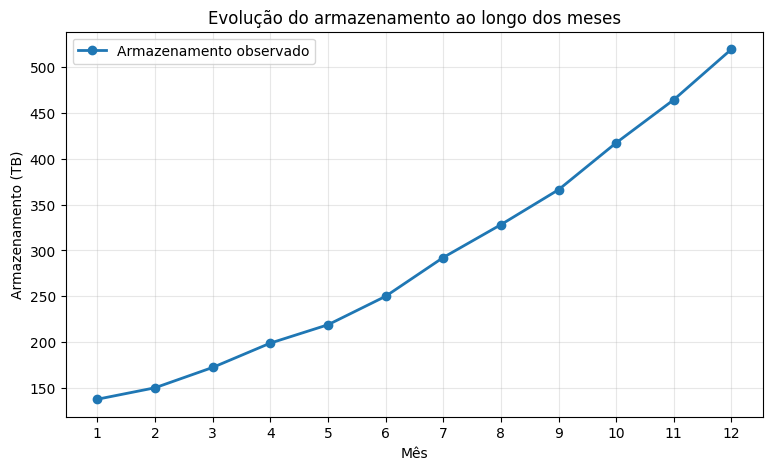

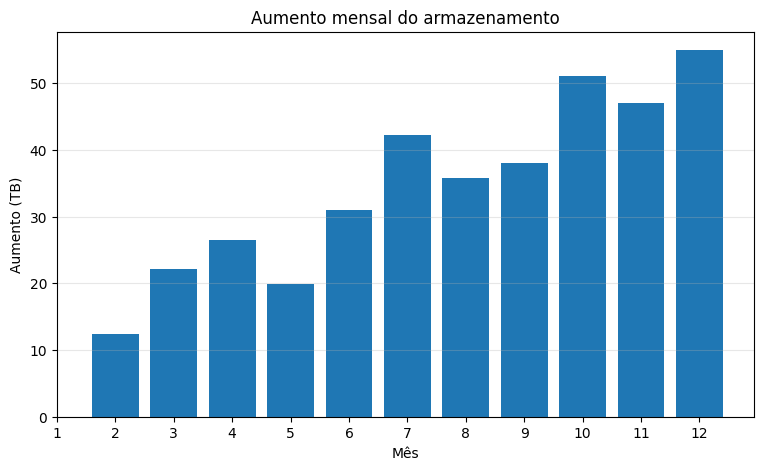

In [5]:
armazenamento["aumento_tb"] = armazenamento["armazenamento_tb"].diff()
armazenamento["aumento_percentual"] = armazenamento["armazenamento_tb"].pct_change() * 100
display(armazenamento)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(meses, valores, marker="o", linewidth=2, label="Armazenamento observado")
ax.set(title="Evolução do armazenamento ao longo dos meses", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.set_xticks(meses); ax.grid(True, alpha=0.3); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(armazenamento["mes"], armazenamento["aumento_tb"])
ax.set(title="Aumento mensal do armazenamento", xlabel="Mês", ylabel="Aumento (TB)")
ax.set_xticks(meses); ax.grid(axis="y", alpha=0.3); plt.show()

## 6. Métodos numéricos implementados provisoriamente

Para não depender da atualização dos módulos compartilhados pelo grupo, as implementações de Gauss, mínimos quadrados, Lagrange, trapézios e Simpson estão temporariamente nesta primeira célula de código. Na integração final, elas deverão ser transferidas para o pacote Python do projeto, conforme a orientação do professor.

- **Sistema linear:** eliminação de Gauss com pivoteamento parcial.
- **Interpolação:** polinômio de Lagrange.
- **Aproximação:** mínimos quadrados para ajustar um polinômio.
- **Integração:** trapézios composto e Simpson composto (com combinação 1/3 e 3/8 quando necessário).

O notebook aplica esses métodos aos dados do Problema 3.

### 6.1 Sistema linear e aproximação por mínimos quadrados

In [6]:
# Ajuste de grau 2: p(m) = a0 + a1*m + a2*m².
grau = 2
coef = ajuste_polinomial_minimos_quadrados(meses, valores, grau=grau)
a0, a1, a2 = coef

valores_ajustados = avaliar_polinomio(coef, meses)
residuos = valores - valores_ajustados
sse = float(np.sum(residuos**2))
sst = float(np.sum((valores - np.mean(valores))**2))
r2 = 1 - sse/sst

print("Coeficientes em ordem crescente:")
print(f"a0 = {a0:.8f}")
print(f"a1 = {a1:.8f}")
print(f"a2 = {a2:.8f}")
print(f"R² = {r2:.6f}")
print(f"Modelo: p(m) = {a0:.6f} + {a1:.6f}m + {a2:.6f}m²")

Coeficientes em ordem crescente:
a0 = 125.14568182
a1 = 9.92926823
a2 = 1.90765984
R² = 0.999574
Modelo: p(m) = 125.145682 + 9.929268m + 1.907660m²


### 6.2 Interpolação de Lagrange

In [7]:
# Exemplo de interpolação entre os meses 5 e 6 usando três pontos próximos.
indices = [3, 4, 5]  # meses 4, 5 e 6
x_interp = meses[indices]
y_interp = valores[indices]
ponto_intermediario = 5.5
estimativa_interpolada = interpolacao_lagrange(x_interp, y_interp, ponto_intermediario)

print(f"Interpolação de Lagrange em m = {ponto_intermediario}: {estimativa_interpolada:.2f} TB")
print("Esse cálculo estima um valor entre observações; não é usado para extrapolar o mês 13.")

Interpolação de Lagrange em m = 5.5: 233.18 TB
Esse cálculo estima um valor entre observações; não é usado para extrapolar o mês 13.


### 6.3 Integração numérica

In [8]:
area_trapezios = trapezios_composto(meses, valores)
area_simpson = simpson_composto(meses, valores)

print(f"Integral aproximada pelos trapézios: {area_trapezios:.2f} TB·mês")
print(f"Integral aproximada por Simpson: {area_simpson:.2f} TB·mês")
print("A integral representa a área aproximada sob a curva de armazenamento entre os meses 1 e 12.")

Integral aproximada pelos trapézios: 3187.64 TB·mês
Integral aproximada por Simpson: 3184.37 TB·mês
A integral representa a área aproximada sob a curva de armazenamento entre os meses 1 e 12.


## 7. Resolução das questões do enunciado

### (a) Função matemática que representa o crescimento

Modelo quadrático obtido por mínimos quadrados:
p(m) = 125.145682 + (9.929268)m + (1.907660)m²
Coeficiente de determinação R² = 0.999574


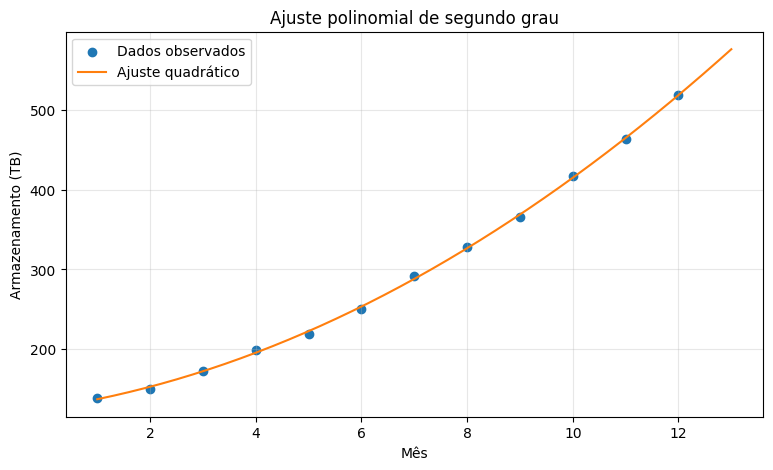

In [9]:
print("Modelo quadrático obtido por mínimos quadrados:")
print(f"p(m) = {a0:.6f} + ({a1:.6f})m + ({a2:.6f})m²")
print(f"Coeficiente de determinação R² = {r2:.6f}")

fig, ax = plt.subplots(figsize=(9, 5))
m_plot = np.linspace(meses.min(), 13, 200)
ax.scatter(meses, valores, label="Dados observados")
ax.plot(m_plot, avaliar_polinomio(coef, m_plot), color="tab:orange", label="Ajuste quadrático")
ax.set(title="Ajuste polinomial de segundo grau", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()

**Interpretação:** escolhemos um polinômio de segundo grau pelo método dos mínimos quadrados. Ele representa a tendência crescente com curvatura observada na série e não precisa passar exatamente por todos os pontos. Os coeficientes são calculados resolvendo o sistema normal por eliminação de Gauss, implementada no pacote. O valor de R² mostra a proporção da variação dos dados explicada pelo ajuste. A escolha é uma aproximação para os dados disponíveis; outros graus poderiam produzir ajustes diferentes.

### (b) Estimativa do volume no próximo mês

In [10]:
mes_proximo = float(meses[-1] + 1)
previsao_proximo_mes = float(avaliar_polinomio(coef, mes_proximo))
print(f"Previsão para o mês {int(mes_proximo)}: {previsao_proximo_mes:.2f} TB")

Previsão para o mês 13: 576.62 TB


### (c) Quando a demanda ultrapassa 600 TB?

In [11]:
capacidade_atual = 600.0

def primeiro_mes_acima(capacidade, coeficientes, inicio, limite=500):
    for mes in range(int(inicio), limite + 1):
        demanda = float(avaliar_polinomio(coeficientes, mes))
        if demanda > capacidade:
            return mes, demanda
    return None, None

mes_600, demanda_600 = primeiro_mes_acima(capacidade_atual, coef, meses[-1] + 1)
print(f"Primeiro mês inteiro em que a estimativa supera 600 TB: mês {mes_600}")
print(f"Demanda estimada nesse mês: {demanda_600:.2f} TB")

Primeiro mês inteiro em que a estimativa supera 600 TB: mês 14
Demanda estimada nesse mês: 638.06 TB


### (d) Quando a capacidade total será ultrapassada em cada plano?

In [12]:
comparacao_planos = expansoes.copy()
comparacao_planos["capacidade_atual_tb"] = capacidade_atual
comparacao_planos["capacidade_total_tb"] = (
    comparacao_planos["capacidade_atual_tb"] + comparacao_planos["capacidade_adicional_tb"]
)

meses_ultrapassagem = []
demandas_ultrapassagem = []
for capacidade in comparacao_planos["capacidade_total_tb"]:
    mes, demanda = primeiro_mes_acima(float(capacidade), coef, meses[-1] + 1)
    meses_ultrapassagem.append(mes)
    demandas_ultrapassagem.append(demanda)

comparacao_planos["primeiro_mes_acima_da_capacidade"] = meses_ultrapassagem
comparacao_planos["demanda_estimada_no_mes_tb"] = demandas_ultrapassagem
display(comparacao_planos)

,plano,capacidade_adicional_tb,capacidade_atual_tb,capacidade_total_tb,primeiro_mes_acima_da_capacidade,demanda_estimada_no_mes_tb
0,A,100,600.0,700.0,15,703.308169
1,B,200,600.0,800.0,17,845.256936
2,C,300,600.0,900.0,18,921.954298


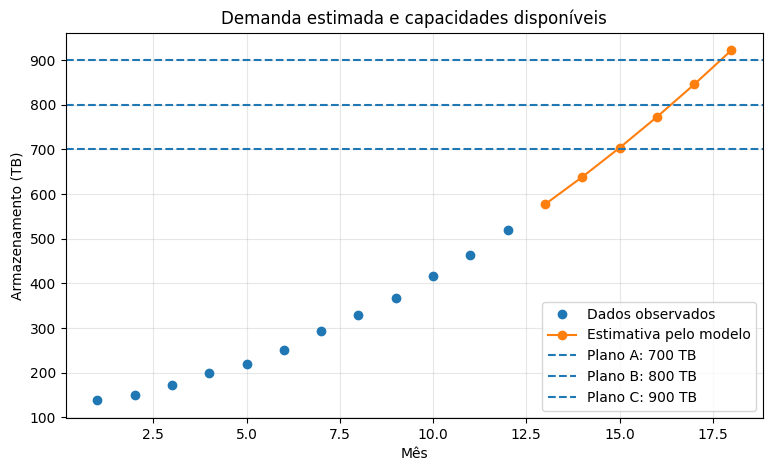

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(meses, valores, "o", label="Dados observados")
m_futuro = np.arange(13, max(meses_ultrapassagem) + 1)
ax.plot(m_futuro, avaliar_polinomio(coef, m_futuro), marker="o", label="Estimativa pelo modelo")
for _, linha in comparacao_planos.iterrows():
    ax.axhline(linha["capacidade_total_tb"], linestyle="--",
               label=f"Plano {linha['plano']}: {linha['capacidade_total_tb']:.0f} TB")
ax.set(title="Demanda estimada e capacidades disponíveis", xlabel="Mês", ylabel="Armazenamento (TB)")
ax.grid(True, alpha=0.3); ax.legend(); plt.show()

## 8. Conclusão

Os dados mostram que o armazenamento passou de 137,99 TB no primeiro mês para 519,14 TB no décimo segundo, um aumento de 381,15 TB (aproximadamente 276,2%). Para representar a tendência e realizar as estimativas, ajustamos um polinômio quadrático por mínimos quadrados, calculando seus coeficientes por meio de um sistema linear resolvido com eliminação de Gauss.

A previsão do próximo mês e os meses de ultrapassagem são calculados pelo modelo e apresentados nas células anteriores. Considerando a capacidade instalada de 600 TB informada no enunciado, cada plano foi avaliado pela capacidade total resultante da soma entre os 600 TB atuais e o acréscimo de 100, 200 ou 300 TB.

As estimativas dependem da hipótese de que a tendência observada continue. Como se trata de extrapolação de apenas 12 meses de dados, os resultados devem ser usados como apoio ao planejamento e revistos quando novos registros estiverem disponíveis. A escolha definitiva também deve considerar margem de segurança, custos e a possibilidade de mudanças no ritmo de crescimento.

## 9. Limitações e observações

- O modelo quadrático é uma aproximação da tendência observada, não uma garantia de crescimento futuro.
- Os meses de ultrapassagem indicam o primeiro mês inteiro em que a previsão fica acima da capacidade.
- A comparação dos planos considera a capacidade atual de 600 TB somada ao acréscimo de 100, 200 ou 300 TB.
- As funções dos métodos numéricos estão provisoriamente no notebook para permitir o avanço individual. Na versão final, deverão ser transferidas para o pacote Python do grupo, sem alterar os pacotes dos demais problemas.